# 10.1.1 Escoamento horizontal estratificado

Reprodução, com o **mfsim** (Python), do primeiro caso do capítulo 10 da tese:
duto horizontal de 1000 m e 0.1 m de diâmetro, 50 elementos finitos (Galerkin),
modelo a dois fluidos (4 equações) com fechamento de padrão estratificado.

Cenário: $q_L = 0.5$ kg/s constante; $q_G$ sobe de 0.1 para 0.13 kg/s em rampa
entre 150 s e 180 s; pressão de saída 100 bar. Condições de contorno Dirichlet
para as vazões na entrada e a pressão na saída.

Os resultados originais do MATLAB (arquivo `CASO10-1-1.mf2`) são sobrepostos
para verificação. Figuras reproduzidas: 10.2 a 10.8 e Tabela 10.1.

In [1]:
import copy, time
import numpy as np
import matplotlib.pyplot as plt
from mfsim.cases import chapter10_case, chapter10_info, legacy_results
from mfsim.network.graph import ports
from mfsim.simulation import simulate, steady_state, build_model
from mfsim.plotting import (
    pipe_surfaces,
    pipe_profiles,
    pipe_timeseries,
    compare_runs,
    legacy_pipe_dict,
    eigenvalue_plot,
)
from mfsim.io_legacy import legacy_states
from mfsim.integrators.jacobian import colored_jacobian

info = chapter10_info("10.1.1")
case, raw = chapter10_case("10.1.1"), legacy_results("10.1.1")
legacy = legacy_pipe_dict(raw, 0)
print(info.title)
print(info.description)
print("Figuras:", info.figures)
print(case.time, case.reference, case.integration)

Escoamento horizontal estratificado
Duto horizontal de 1000 m, D=0.1 m, 50 elementos, Galerkin, modelo a 4 equações com padrão estratificado fixo. qL=0.5 kg/s; qG sobe de 0.1 para 0.13 kg/s entre 150 e 180 s. Pressão de saída 100 bar.
Figuras: Figs. 10.2-10.8, Tabela 10.1
TimeSpec(t0=0.0, tf=3000.0, dt_out=10.0) ReferenceSpec(PR=10000000.0, state_ref=()) IntegrationSpec(integrator='bdf', method_quadrature=2, max_step=1.0, atol=0.001, rtol=0.001, backend='numpy', tol_range=None, atol_P=None, atol_q=None, first_step=None, max_order=None, max_newton=None, newton_tol=None, min_step=None, slow_exit=None, predict_space=None, jt_refresh=None, accumulate=False, tight_bounds=False, galerkin_band=None, extra=())


## Estado estacionário (Figura 10.2)

A condição inicial é o estado estacionário obtido anulando as derivadas temporais
do modelo dinâmico. Partimos de uma estimativa baseada no nível estratificado de
equilíbrio (modelo de Taitel & Dukler) e resolvemos o sistema algébrico por Newton
com Jacobiana esparsa. O resultado é comparado com o estado inicial gravado pelo MATLAB.

**Observação importante.** Com a fração de gás *livre* na entrada (condição de
contorno "ausente", como no arquivo original) a Jacobiana do sistema discretizado
tem um autovalor nulo (ver Figura 10.7 abaixo): o estado estacionário discreto não
é único e o Newton pode convergir para perfis de fração de gás não uniformes que
dependem da malha. Com gradiente nulo (von Neumann) na entrada o estado é único
e coincide com o da tese para todas as malhas. Por isso, no estudo de malha
usa-se von Neumann; na simulação principal parte-se do estado gravado pelo MATLAB.

In [2]:
case_ss = copy.deepcopy(case)
case_ss.pipes[0].ports_in = ports((3, 1, 2, 2))  # von Neumann para alphaG na entrada
case_ss.pipes[0].ic = None
t0 = time.time()
model_ss, X_ss, info_ss = steady_state(case_ss, X0="auto", verbose=True)
print(f"convergiu={info_ss['converged']} resíduo={info_ss['residual']:.2e} em {time.time()-t0:.2f} s")
Tl, Xl = legacy_states(raw)
E, Ys, _, _ = model_ss.assemble(0.0, X_ss)
print("fração de gás entrada/saída (Python):", Ys[0][0, 0], Ys[0][-1, 0], " | MATLAB:", Xl[0, 0], Xl[-3, 0])
print("pressão de entrada (bar): Python", Ys[0][0, 1] * 100, " | MATLAB", Xl[1, 0] * 100)

  it 0  |F| = 7.857e-02
  it 1  |F| = 4.236e-03  (lambda=1)
  it 2  |F| = 5.045e-05  (lambda=1)
  it 3  |F| = 1.145e-08  (lambda=1)
  it 4  |F| = 1.381e-12  (lambda=1)
convergiu=True resíduo=1.38e-12 em 0.20 s
fração de gás entrada/saída (Python): 0.4636731443963192 0.46446057524264645  | MATLAB: 0.46363795412029807 0.46371001390047045
pressão de entrada (bar): Python 100.0283084556276  | MATLAB 100.02831036214674


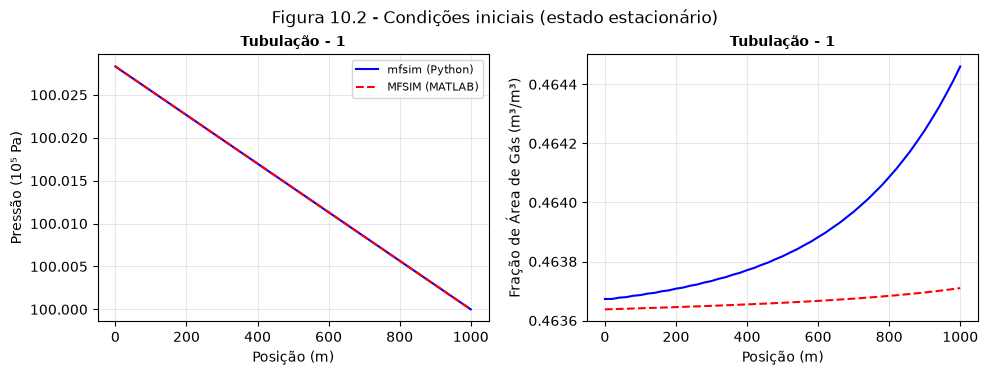

In [3]:
from mfsim.results import Results

res0 = Results(model_ss, [0.0], X_ss[:, None])
fig = pipe_profiles(res0, keys=("P_bar", "alphaG"), it=0, legacy=legacy)
fig.suptitle("Figura 10.2 - Condições iniciais (estado estacionário)", y=1.03)
plt.show()

## Simulação dinâmica (Figura 10.3)

Integração a partir do estado inicial gravado pelo MATLAB, com o BDF implícito
próprio (ordem variável 1-2, passo adaptativo, Newton modificado com Jacobiana
esparsa colorida). As condições de contorno são as do arquivo original.

[implicit BDF] steps=168 rejected=14 rhs=3237 jac=36 | 0.8s
tempo de CPU: 0.84 s | {'success': True, 'n_steps': 168, 'n_rejected': 14, 'n_rhs': 3237, 'n_jac': 36, 'cpu': 0.8358509540557861}


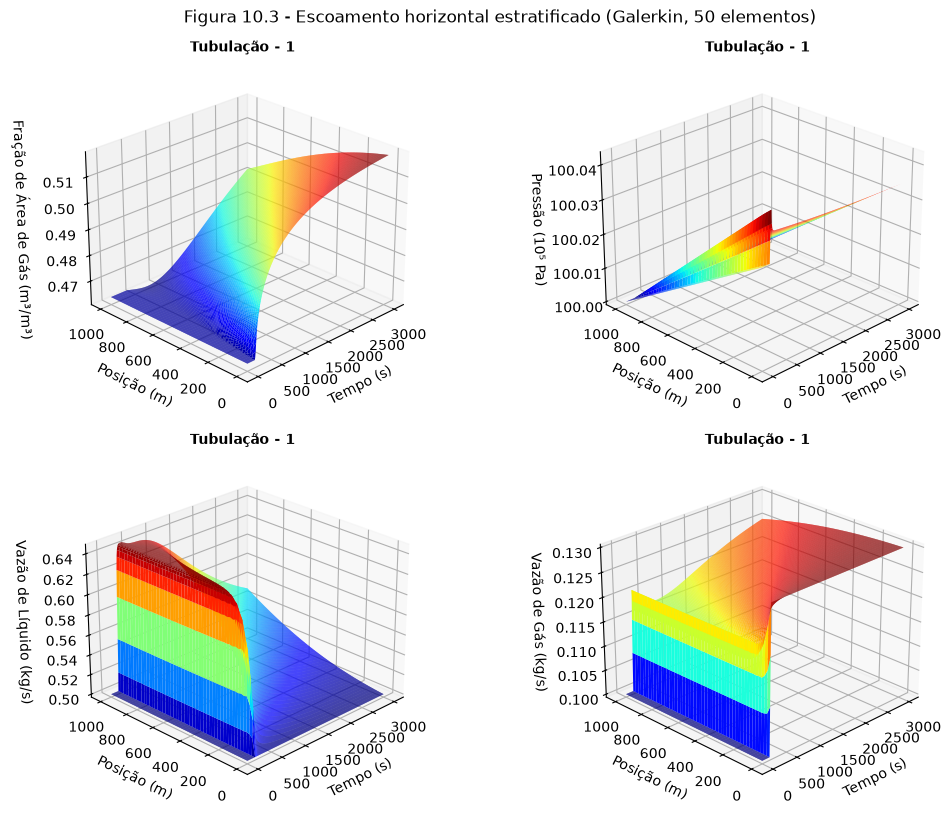

In [4]:
t0 = time.time()
res = simulate(case, integrator="implicit", rtol=1e-4, atol=1e-6, max_step=np.inf)
print(f"tempo de CPU: {time.time()-t0:.2f} s | {res.info}")
fig = pipe_surfaces(res, 0)
fig.suptitle("Figura 10.3 - Escoamento horizontal estratificado (Galerkin, 50 elementos)", y=1.02)
plt.show()

### Comparação Python × MATLAB em três posições do duto
(linhas cheias: mfsim; tracejadas: resultados originais gravados no `.mf2`)

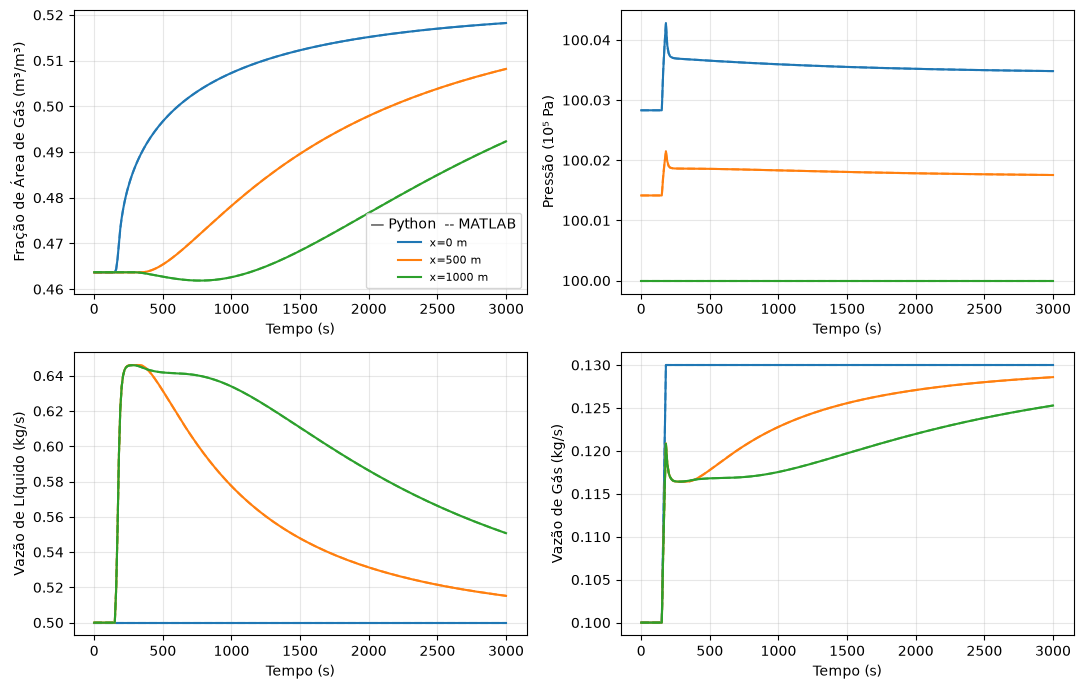

alphaG : máx |Python - MATLAB| = 3.28e-05  (faixa MATLAB 5.64e-02)
PT     : máx |Python - MATLAB| = 3.54e-06  (faixa MATLAB 4.22e-04)
qL     : máx |Python - MATLAB| = 4.73e-04  (faixa MATLAB 1.46e-01)
qG     : máx |Python - MATLAB| = 1.14e-04  (faixa MATLAB 3.00e-02)


In [5]:
fig = pipe_timeseries(res, 0, legacy=legacy)
plt.show()
slots = res.model.state_slots()
for s, name in enumerate(["alphaG", "PT", "qL", "qG"]):
    m = slots == s
    print(
        f"{name:7s}: máx |Python - MATLAB| = {np.max(np.abs(res.X[m] - Xl[m])):.2e}  (faixa MATLAB {np.ptp(Xl[m]):.2e})"
    )

## Sensibilidade de malha - Galerkin (Figura 10.4) e diferenças finitas (Figura 10.5)

Para cada malha o estado estacionário é recalculado e a simulação repetida.
Os tempos de CPU reproduzem a Tabela 10.1 (na tese: 17 a 132 s em 2010; aqui
com o integrador implícito próprio).

In [6]:
def run_mesh(nel, method):
    c = copy.deepcopy(case_ss)
    c.pipes[0].n_elements = np.array([nel])
    c.pipes[0].ic = None
    c.set_method(method)
    t0 = time.time()
    steady_state(c, X0="auto", verbose=False)
    r = simulate(c, integrator="implicit", rtol=1e-4, atol=1e-6, max_step=np.inf, progress=False)
    return r, time.time() - t0


meshes = [5, 10, 25, 50, 100]
runs = {}
table = []
for method in ["galerkin", "fd_central"]:
    for nel in meshes:
        r, cpu = run_mesh(nel, method)
        runs[(method, nel)] = r
        table.append((method, nel, cpu, r.info["n_steps"]))
        print(f"{method:11s} N={nel:4d}: {cpu:6.2f} s, {r.info['n_steps']} passos")

galerkin    N=   5:   0.16 s, 156 passos


galerkin    N=  10:   0.22 s, 167 passos


galerkin    N=  25:   0.37 s, 169 passos


galerkin    N=  50:   0.65 s, 173 passos


galerkin    N= 100:   2.46 s, 180 passos
fd_central  N=   5:   0.15 s, 153 passos


fd_central  N=  10:   0.17 s, 161 passos
fd_central  N=  25:   0.19 s, 167 passos


fd_central  N=  50:   0.23 s, 169 passos


fd_central  N= 100:   0.23 s, 169 passos


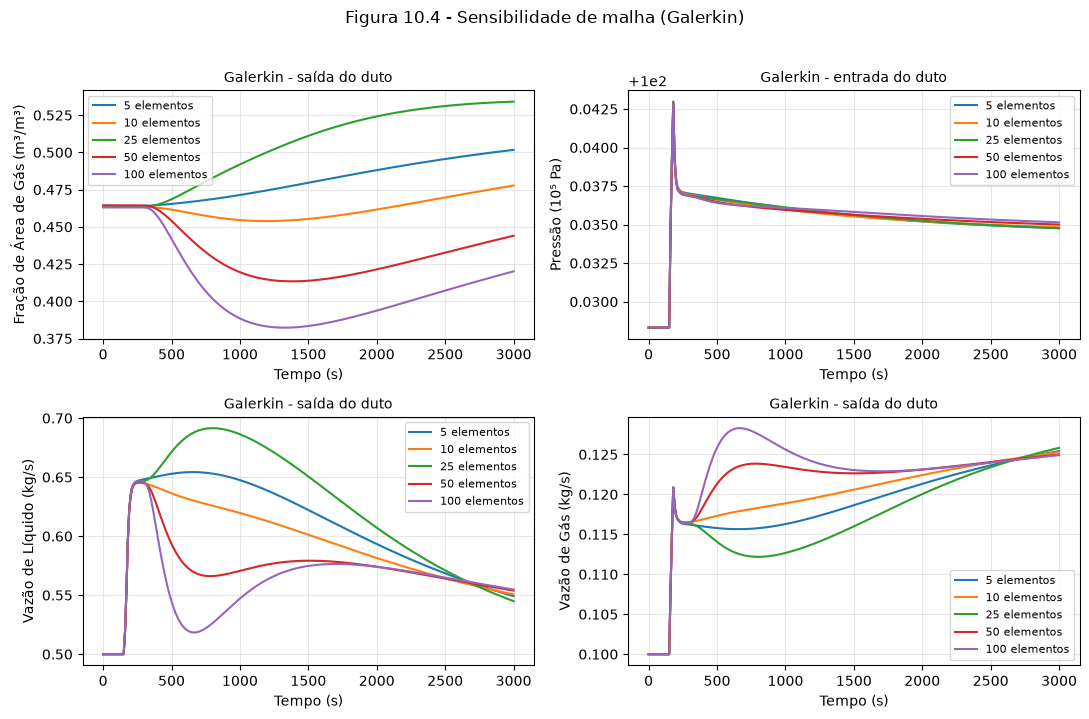

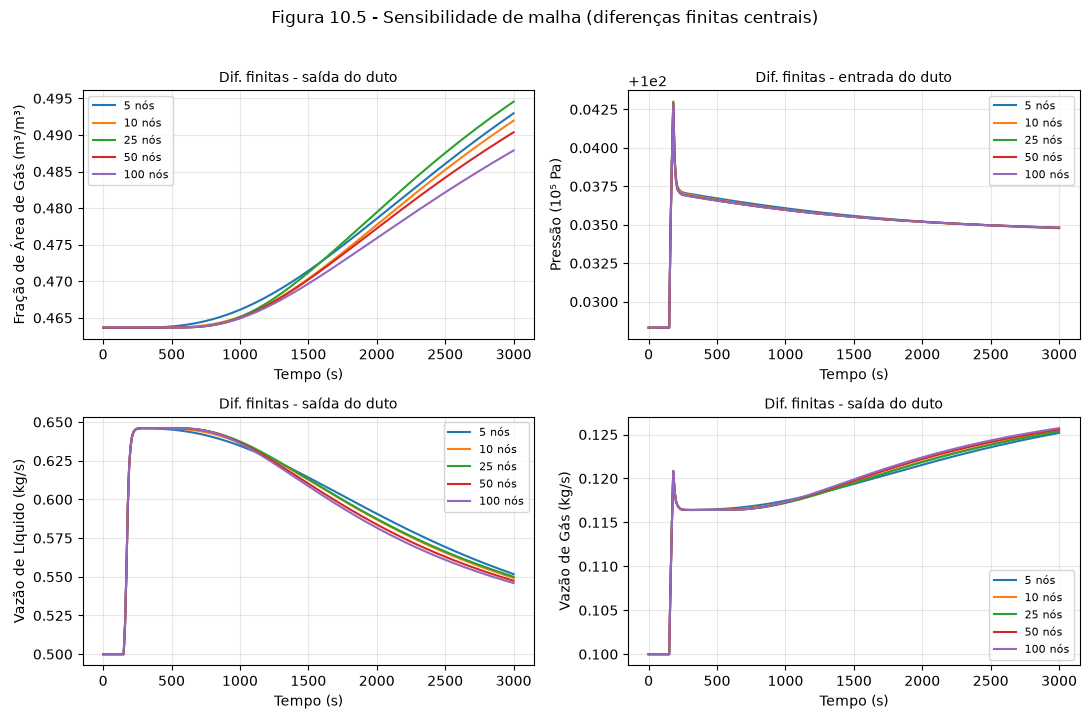

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, key in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
    compare_runs(
        {f"{n} elementos": runs[("galerkin", n)] for n in meshes},
        key=key,
        node=-1 if key != "P_bar" else 0,
        ax=ax,
        title=f"Galerkin - {'saída' if key != 'P_bar' else 'entrada'} do duto",
    )
fig.suptitle("Figura 10.4 - Sensibilidade de malha (Galerkin)", y=1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, key in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
    compare_runs(
        {f"{n} nós": runs[("fd_central", n)] for n in meshes},
        key=key,
        node=-1 if key != "P_bar" else 0,
        ax=ax,
        title=f"Dif. finitas - {'saída' if key != 'P_bar' else 'entrada'} do duto",
    )
fig.suptitle("Figura 10.5 - Sensibilidade de malha (diferenças finitas centrais)", y=1.02)
fig.tight_layout()
plt.show()

## Comparação entre Galerkin e diferenças finitas (Figura 10.6) e Tabela 10.1

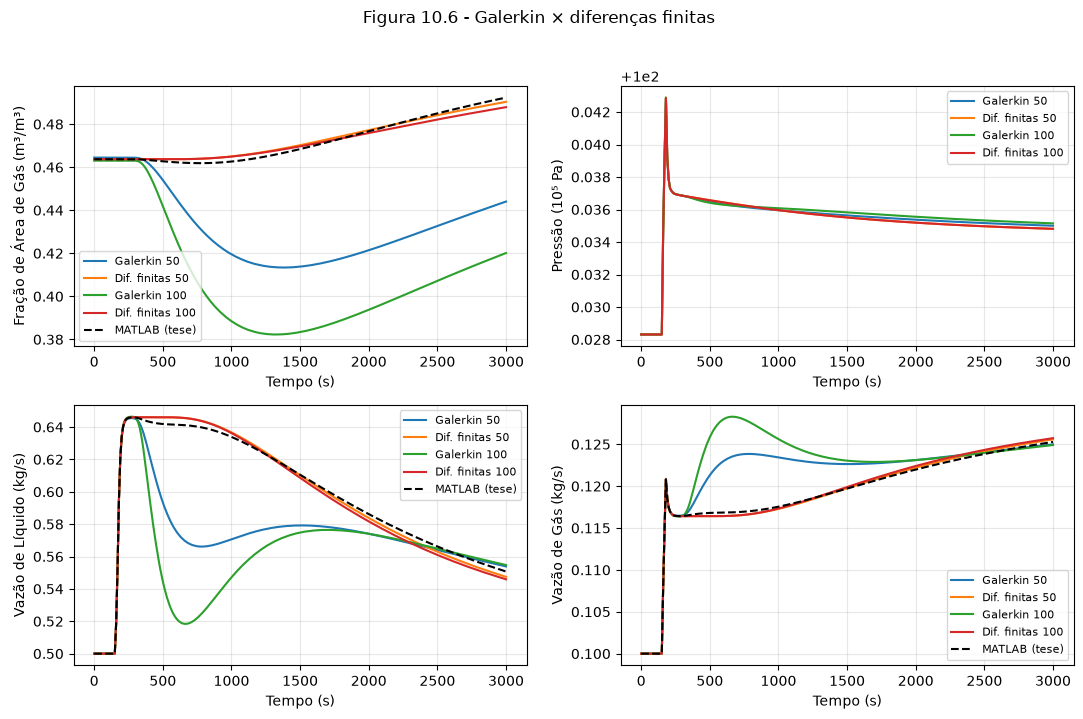

Tabela 10.1 - tempos computacionais (estado estacionário + simulação, Python)
Método           N   CPU (s)  passos
galerkin         5     0.16s     156
galerkin        10     0.22s     167
galerkin        25     0.37s     169
galerkin        50     0.65s     173
galerkin       100     2.46s     180
fd_central       5     0.15s     153
fd_central      10     0.17s     161
fd_central      25     0.19s     167
fd_central      50     0.23s     169
fd_central     100     0.23s     169


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, key in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
    compare_runs(
        {
            "Galerkin 50": runs[("galerkin", 50)],
            "Dif. finitas 50": runs[("fd_central", 50)],
            "Galerkin 100": runs[("galerkin", 100)],
            "Dif. finitas 100": runs[("fd_central", 100)],
        },
        key=key,
        node=-1 if key != "P_bar" else 0,
        ax=ax,
        legacy=legacy if key != "P_bar" else None,
    )
fig.suptitle("Figura 10.6 - Galerkin × diferenças finitas", y=1.02)
fig.tight_layout()
plt.show()

print("Tabela 10.1 - tempos computacionais (estado estacionário + simulação, Python)")
print(f"{'Método':12s} {'N':>5s} {'CPU (s)':>9s} {'passos':>7s}")
for method, nel, cpu, steps in table:
    print(f"{method:12s} {nel:5d} {cpu:8.2f}s {steps:7d}")

## Autovalores da Jacobiana no estado final (Figuras 10.7 e 10.8)

Formulação 1: condições de contorno do arquivo (vazões e pressão de saída Dirichlet,
fração de gás livre na entrada: 201 estados). Formulação 2: fração de gás na
entrada com gradiente nulo imposto (200 estados). Com a fração de gás livre na
entrada surge um autovalor nulo (modo neutro: a fração de gás de entrada não é
determinada pelas equações), que explica a não-unicidade do estado estacionário
discutida acima; com gradiente nulo todos os autovalores ficam no semiplano esquerdo.

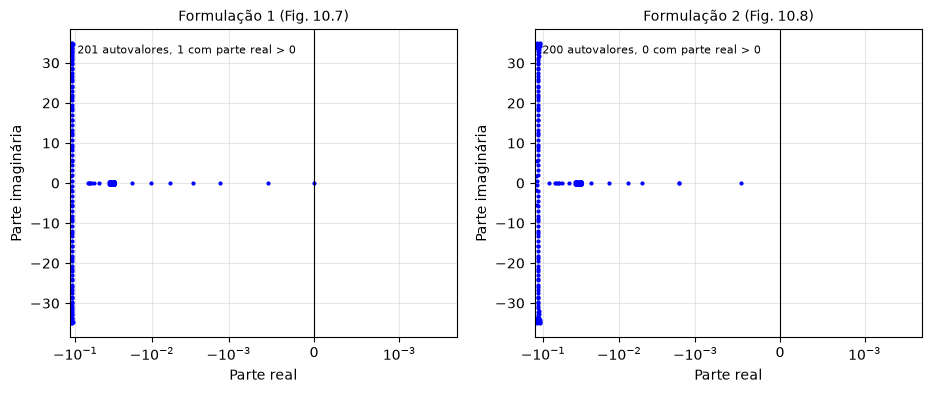

máx parte real: formulação 1 = 1.185952351307293e-11 | formulação 2 = -0.00046499390509174425


In [9]:
def jacobian_eigs(c, X):
    m = build_model(c)
    f0 = m.rhs(c.time.tf, X)
    n = m.n_states
    J = np.empty((n, n))
    for j in range(n):
        h = 1e-7 * abs(X[j]) + 1e-9
        xp = X.copy()
        xp[j] += h
        J[:, j] = (m.rhs(c.time.tf, xp) - f0) / h
    return np.linalg.eigvals(J)


ev1 = jacobian_eigs(case, res.X[:, -1])
c2 = copy.deepcopy(case_ss)
res2 = simulate(c2, integrator="implicit", rtol=1e-4, atol=1e-6, max_step=np.inf, progress=False)
ev2 = jacobian_eigs(c2, res2.X[:, -1])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
eigenvalue_plot(ev1, axes[0], "Formulação 1 (Fig. 10.7)")
eigenvalue_plot(ev2, axes[1], "Formulação 2 (Fig. 10.8)")
for ax in axes:
    ax.set_xscale("symlog", linthresh=1e-3)
plt.show()
print("máx parte real: formulação 1 =", ev1.real.max(), "| formulação 2 =", ev2.real.max())

## Lado direito compilado (JAX)
A mesma simulação com `simulate(..., jax=True)`: lado direito compilado por
`jax.jit` e Jacobiana exata por diferenciação automática (`mfsim/compiled.py`, o mesmo código numpy com o backend JAX),
no lugar das diferenças finitas coloridas. O resultado deve coincidir com a versão
numpy dentro da tolerância do integrador (as sequências de passos podem diferir
porque a Jacobiana muda o Newton); o ganho de tempo cresce com o número de passos
e de Jacobianas.

In [10]:
from mfsim.notebook_utils import jax_comparison

res_jax = jax_comparison(case, res, rtol=1e-4, atol=1e-6)

JAX: 0.32 s (168 passos; compilação 0.46 s, uma vez por modelo) | numpy: 0.84 s (168 passos) | diferença máxima relativa dos estados 9.9e-07
